DOWNLOADING STOCK DATA
Stock       : AAPL
Start Date  : 2015-01-01
End Date    : 2024-12-31


[*********************100%***********************]  1 of 1 completed

Downloaded rows: 2515

DATA PREPROCESSING
Total data       : 2515
Training data    : 2012
Testing data     : 503

X_train shape: (1952, 60, 1)
y_train shape: (1952,)
X_test shape : (503, 60, 1)
y_test shape : (503,)

BUILDING LSTM MODEL





/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 100)        │        40,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 100)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 60, 100)        │        80,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 60, 100)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 50)             │        30,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 152,701 (596.49 KB)

 Trainable params: 152,701 (596.49 KB)

 Non-trainable params: 0 (0.00 B)


TRAINING MODEL
Epoch 1/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 121ms/step - loss: 0.0160
Epoch 2/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 6s 100ms/step - loss: 0.0032
Epoch 3/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 7s 121ms/step - loss: 0.0028
Epoch 4/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 6s 99ms/step - loss: 0.0024
Epoch 5/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 7s 121ms/step - loss: 0.0022
Epoch 6/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 6s 98ms/step - loss: 0.0019
Epoch 7/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - loss: 0.0019
Epoch 8/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 7s 121ms/step - loss: 0.0021
Epoch 9/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - loss: 0.0018
Epoch 10/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 7s 121ms/step - loss: 0.0015
Epoch 11/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step - loss: 0.0015
Epoch 12/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 99ms/step - loss: 0.0017
Epoch 13/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 98ms/step - loss: 0.0014
Epoch 14/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - loss: 0.0013
Epoch 15/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 11

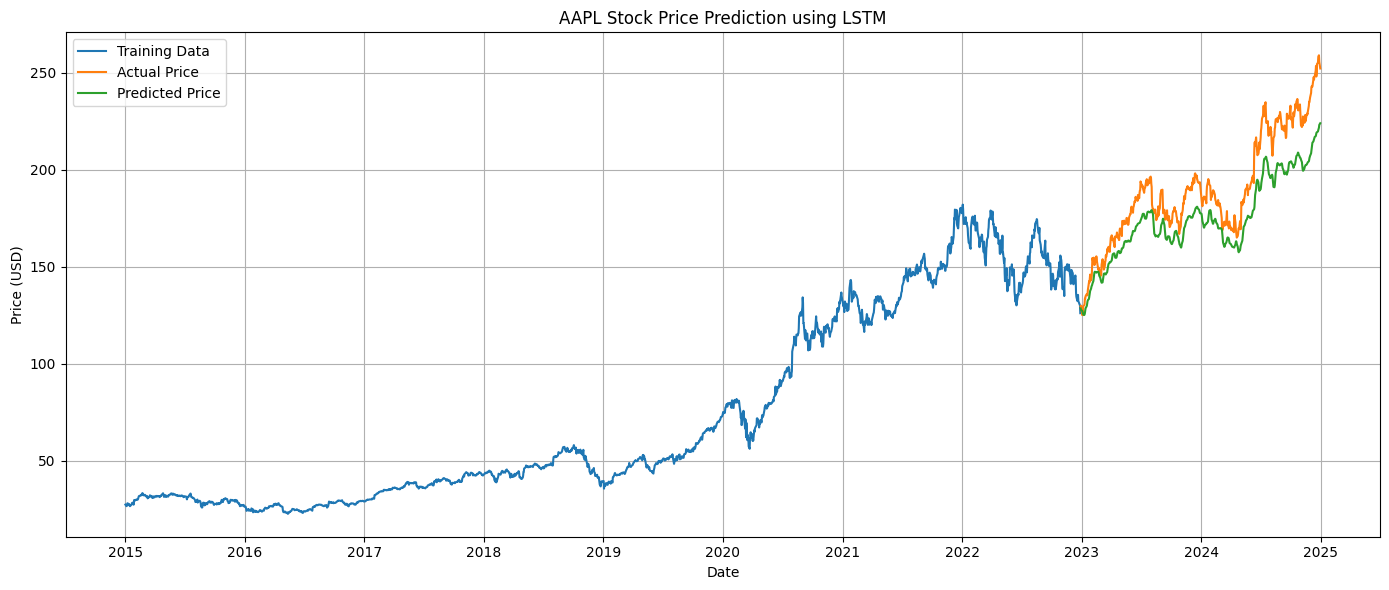

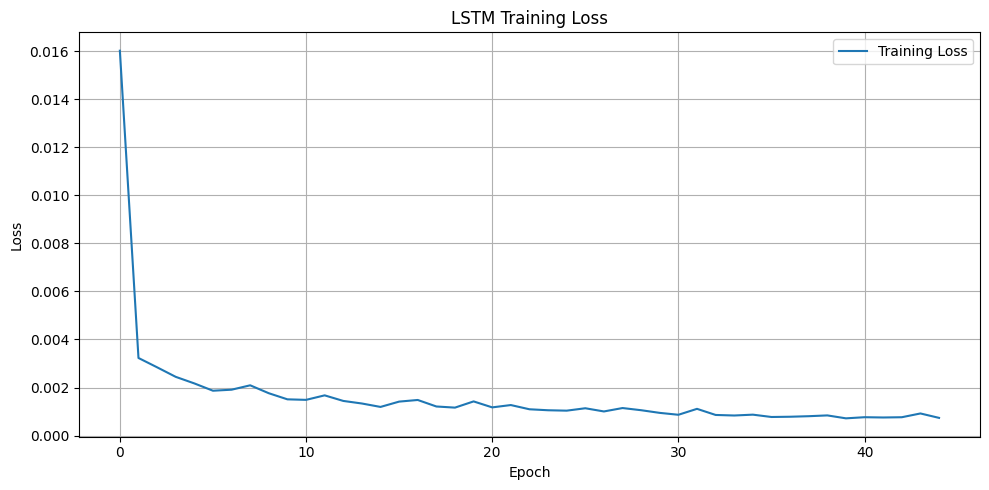


FUTURE PRICE FORECAST



--- Next 10-Day Forecast ---
Day  1: $223.79
Day  2: $219.67
Day  3: $212.82
Day  4: $204.66
Day  5: $196.41
Day  6: $188.87
Day  7: $182.11
Day  8: $176.24
Day  9: $171.21
Day 10: $167.18

MODEL SAVED
Saved as: lstm_stock_model.h5
Graph saved as: lstm_prediction_result.png
Loss graph saved as: training_loss.png

FINAL RESULT
Model Accuracy : 92.39%
R2 Score       : 0.6270
RMSE           : 17.06
MAE            : 15.15
MAPE           : 7.61%


In [ ]:
"""
Stock Price Prediction using LSTM
=================================
Complete end-to-end pipeline:

1. Download stock data using Yahoo Finance
2. Preprocess and scale data
3. Create sequences
4. Build LSTM model
5. Train model
6. Evaluate using RMSE, MAE, MAPE, R2
7. Calculate accuracy = 100 - MAPE
8. Plot actual vs predicted prices
9. Predict next 10 days
10. Save trained model
"""

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


# ============================================================
# 2. CONFIGURATION
# ============================================================

TICKER = "AAPL"

START_DATE = "2015-01-01"
END_DATE = "2024-12-31"

# Use previous 60 days to predict next day
SEQUENCE_LENGTH = 60

# 80% training, 20% testing
TRAIN_SPLIT_RATIO = 0.8

EPOCHS = 50
BATCH_SIZE = 32

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)


# ============================================================
# 3. DATA COLLECTION
# ============================================================

def load_data(ticker, start, end):

    print("=" * 60)
    print("DOWNLOADING STOCK DATA")
    print("=" * 60)

    print(f"Stock       : {ticker}")
    print(f"Start Date  : {start}")
    print(f"End Date    : {end}")

    df = yf.download(
        ticker,
        start=start,
        end=end,
        auto_adjust=False
    )

    # Keep only Close price
    df = df[["Close"]].dropna()

    print(f"Downloaded rows: {len(df)}")

    return df


# ============================================================
# 4. DATA PREPROCESSING
# ============================================================

def preprocess_data(df, sequence_length, train_split_ratio):

    print("\n" + "=" * 60)
    print("DATA PREPROCESSING")
    print("=" * 60)

    data = df.values

    # Calculate training size
    train_size = int(len(data) * train_split_ratio)

    print(f"Total data       : {len(data)}")
    print(f"Training data    : {train_size}")
    print(f"Testing data     : {len(data) - train_size}")

    # --------------------------------------------------------
    # Training and testing data
    # --------------------------------------------------------

    train_data = data[:train_size]

    # Keep previous 60 days for test sequence
    test_data = data[train_size - sequence_length:]

    # --------------------------------------------------------
    # Scaling
    # --------------------------------------------------------

    scaler = MinMaxScaler(feature_range=(0, 1))

    # Fit scaler ONLY on training data
    scaled_train = scaler.fit_transform(train_data)

    scaled_test = scaler.transform(test_data)

    # --------------------------------------------------------
    # Create sequences
    # --------------------------------------------------------

    def create_sequences(dataset):

        X = []
        y = []

        for i in range(sequence_length, len(dataset)):

            # Previous 60 days
            X.append(
                dataset[i - sequence_length:i, 0]
            )

            # Current day
            y.append(
                dataset[i, 0]
            )

        return np.array(X), np.array(y)

    X_train, y_train = create_sequences(scaled_train)

    X_test, y_test = create_sequences(scaled_test)

    # --------------------------------------------------------
    # Reshape for LSTM
    # --------------------------------------------------------

    # LSTM expects:
    # [samples, time steps, features]

    X_train = X_train.reshape(
        X_train.shape[0],
        X_train.shape[1],
        1
    )

    X_test = X_test.reshape(
        X_test.shape[0],
        X_test.shape[1],
        1
    )

    print(f"\nX_train shape: {X_train.shape}")
    print(f"y_train shape: {y_train.shape}")

    print(f"X_test shape : {X_test.shape}")
    print(f"y_test shape : {y_test.shape}")

    return (
        X_train,
        y_train,
        X_test,
        y_test,
        scaler,
        train_size
    )


# ============================================================
# 5. BUILD LSTM MODEL
# ============================================================

def build_model(input_shape):

    print("\n" + "=" * 60)
    print("BUILDING LSTM MODEL")
    print("=" * 60)

    model = Sequential()

    # First LSTM layer
    model.add(
        LSTM(
            units=100,
            return_sequences=True,
            input_shape=input_shape
        )
    )

    model.add(Dropout(0.2))

    # Second LSTM layer
    model.add(
        LSTM(
            units=100,
            return_sequences=True
        )
    )

    model.add(Dropout(0.2))

    # Third LSTM layer
    model.add(
        LSTM(
            units=50,
            return_sequences=False
        )
    )

    model.add(Dropout(0.2))

    # Dense layers
    model.add(
        Dense(
            units=25,
            activation="relu"
        )
    )

    model.add(
        Dense(
            units=1
        )
    )

    # Compile
    model.compile(
        optimizer="adam",
        loss="mean_squared_error"
    )

    return model


# ============================================================
# 6. TRAIN MODEL
# ============================================================

def train_model(model, X_train, y_train):

    print("\n" + "=" * 60)
    print("TRAINING MODEL")
    print("=" * 60)

    early_stop = EarlyStopping(
        monitor="loss",
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=1
    )

    return history


# ============================================================
# 7. EVALUATE MODEL
# ============================================================

def evaluate_model(
    model,
    X_test,
    y_test,
    scaler
):

    print("\n" + "=" * 60)
    print("MODEL EVALUATION")
    print("=" * 60)

    # --------------------------------------------------------
    # Make predictions
    # --------------------------------------------------------

    predictions_scaled = model.predict(
        X_test,
        verbose=0
    )

    # Convert scaled values back to actual prices
    predictions = scaler.inverse_transform(
        predictions_scaled
    )

    y_test_actual = scaler.inverse_transform(
        y_test.reshape(-1, 1)
    )

    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------

    rmse = np.sqrt(
        mean_squared_error(
            y_test_actual,
            predictions
        )
    )

    # --------------------------------------------------------
    # MAE
    # --------------------------------------------------------

    mae = mean_absolute_error(
        y_test_actual,
        predictions
    )

    # --------------------------------------------------------
    # MAPE
    # --------------------------------------------------------

    mape = np.mean(
        np.abs(
            (y_test_actual - predictions)
            / y_test_actual
        )
    ) * 100

    # --------------------------------------------------------
    # R2 Score
    # --------------------------------------------------------

    r2 = r2_score(
        y_test_actual,
        predictions
    )

    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    accuracy = 100 - mape

    # Prevent negative accuracy
    if accuracy < 0:
        accuracy = 0

    # --------------------------------------------------------
    # Display results
    # --------------------------------------------------------

    print("\n--- Evaluation Metrics ---")

    print(f"RMSE     : {rmse:.2f}")
    print(f"MAE      : {mae:.2f}")
    print(f"MAPE     : {mape:.2f}%")
    print(f"R2 Score : {r2:.4f}")
    print(f"Accuracy : {accuracy:.2f}%")

    print("\nNote:")
    print("Accuracy is calculated as:")
    print("Accuracy = 100 - MAPE")

    metrics = {
        "RMSE": rmse,
        "MAE": mae,
        "MAPE": mape,
        "R2": r2,
        "Accuracy": accuracy
    }

    return (
        predictions,
        y_test_actual,
        metrics
    )


# ============================================================
# 8. PLOT ACTUAL VS PREDICTED
# ============================================================

def plot_results(
    df,
    train_size,
    predictions,
    y_test_actual,
    ticker
):

    print("\n" + "=" * 60)
    print("CREATING PREDICTION GRAPH")
    print("=" * 60)

    plt.figure(figsize=(14, 6))

    # Training data
    plt.plot(
        df.index[:train_size],
        df["Close"].iloc[:train_size],
        label="Training Data"
    )

    # Test dates
    test_dates = df.index[train_size:]

    # Actual prices
    plt.plot(
        test_dates,
        y_test_actual.flatten(),
        label="Actual Price"
    )

    # Predicted prices
    plt.plot(
        test_dates,
        predictions.flatten(),
        label="Predicted Price"
    )

    plt.title(
        f"{ticker} Stock Price Prediction using LSTM"
    )

    plt.xlabel("Date")

    plt.ylabel("Price (USD)")

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    # Save graph
    plt.savefig(
        "lstm_prediction_result.png",
        dpi=150
    )

    plt.show()


# ============================================================
# 9. PLOT TRAINING LOSS
# ============================================================

def plot_training_loss(history):

    plt.figure(figsize=(10, 5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.title("LSTM Training Loss")

    plt.xlabel("Epoch")

    plt.ylabel("Loss")

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        "training_loss.png",
        dpi=150
    )

    plt.show()


# ============================================================
# 10. FUTURE PRICE FORECASTING
# ============================================================

def forecast_future(
    model,
    df,
    scaler,
    sequence_length,
    days_ahead=10
):

    print("\n" + "=" * 60)
    print("FUTURE PRICE FORECAST")
    print("=" * 60)

    # Get last 60 closing prices
    last_sequence = (
        df["Close"]
        .values[-sequence_length:]
        .reshape(-1, 1)
    )

    # Scale the sequence
    scaled_sequence = scaler.transform(
        last_sequence
    )

    # Reshape for LSTM
    current_batch = scaled_sequence.reshape(
        1,
        sequence_length,
        1
    )

    future_predictions = []

    # --------------------------------------------------------
    # Predict one day at a time
    # --------------------------------------------------------

    for day in range(days_ahead):

        next_pred = model.predict(
            current_batch,
            verbose=0
        )[0]

        future_predictions.append(
            next_pred[0]
        )

        # Add prediction to sequence
        current_batch = np.concatenate(
            [
                current_batch[:, 1:, :],
                next_pred.reshape(1, 1, 1)
            ],
            axis=1
        )

    # Convert predictions back to actual prices
    future_predictions = np.array(
        future_predictions
    ).reshape(-1, 1)

    future_predictions = scaler.inverse_transform(
        future_predictions
    )

    return future_predictions


# ============================================================
# 11. DISPLAY FUTURE FORECAST
# ============================================================

def display_future_prices(future_prices):

    print("\n--- Next 10-Day Forecast ---")

    for i, price in enumerate(
        future_prices,
        start=1
    ):

        print(
            f"Day {i:2d}: ${price[0]:.2f}"
        )


# ============================================================
# 12. MAIN FUNCTION
# ============================================================

def main():

    # --------------------------------------------------------
    # Step 1: Download data
    # --------------------------------------------------------

    df = load_data(
        TICKER,
        START_DATE,
        END_DATE
    )

    # --------------------------------------------------------
    # Step 2: Preprocess data
    # --------------------------------------------------------

    (
        X_train,
        y_train,
        X_test,
        y_test,
        scaler,
        train_size
    ) = preprocess_data(
        df,
        SEQUENCE_LENGTH,
        TRAIN_SPLIT_RATIO
    )

    # --------------------------------------------------------
    # Step 3: Build model
    # --------------------------------------------------------

    model = build_model(
        (
            X_train.shape[1],
            1
        )
    )

    # Display model
    print("\n")
    model.summary()

    # --------------------------------------------------------
    # Step 4: Train model
    # --------------------------------------------------------

    history = train_model(
        model,
        X_train,
        y_train
    )

    # --------------------------------------------------------
    # Step 5: Evaluate model
    # --------------------------------------------------------

    (
        predictions,
        y_test_actual,
        metrics
    ) = evaluate_model(
        model,
        X_test,
        y_test,
        scaler
    )

    # --------------------------------------------------------
    # Step 6: Plot actual vs predicted
    # --------------------------------------------------------

    plot_results(
        df,
        train_size,
        predictions,
        y_test_actual,
        TICKER
    )

    # --------------------------------------------------------
    # Step 7: Plot training loss
    # --------------------------------------------------------

    plot_training_loss(history)

    # --------------------------------------------------------
    # Step 8: Predict next 10 days
    # --------------------------------------------------------

    future_prices = forecast_future(
        model,
        df,
        scaler,
        SEQUENCE_LENGTH,
        days_ahead=10
    )

    # Display future prices
    display_future_prices(
        future_prices
    )

    # --------------------------------------------------------
    # Step 9: Save model
    # --------------------------------------------------------

    model.save(
        "lstm_stock_model.h5"
    )

    print("\n" + "=" * 60)
    print("MODEL SAVED")
    print("=" * 60)

    print(
        "Saved as: lstm_stock_model.h5"
    )

    print(
        "Graph saved as: lstm_prediction_result.png"
    )

    print(
        "Loss graph saved as: training_loss.png"
    )

    # --------------------------------------------------------
    # Final result
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print("FINAL RESULT")
    print("=" * 60)

    print(
        f"Model Accuracy : {metrics['Accuracy']:.2f}%"
    )

    print(
        f"R2 Score       : {metrics['R2']:.4f}"
    )

    print(
        f"RMSE           : {metrics['RMSE']:.2f}"
    )

    print(
        f"MAE            : {metrics['MAE']:.2f}"
    )

    print(
        f"MAPE           : {metrics['MAPE']:.2f}%"
    )


# ============================================================
# 13. RUN PROGRAM
# ============================================================

if __name__ == "__main__":
    main()